In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
print("All libraries are successfully imported")

All libraries are successfully imported


In [27]:
study_hours = [1,2,3,4,5]
marks = [35,40,50,55,65]

df = pd.DataFrame({"Study Hours" : study_hours,
                   "Marks" : marks})
df

,Study Hours,Marks
0,1,35
1,2,40
2,3,50
3,4,55
4,5,65


In [28]:
X = df['Study Hours'].values
Y = df['Marks'].values

In [29]:
X

array([1, 2, 3, 4, 5])

In [30]:
Y

array([35, 40, 50, 55, 65])

In [31]:
mean_x = np.mean(X)
mean_y = np.mean(Y)

n = len(X)

numer = 0 #counter
denom = 0 #counter

for i in range(n):
    numer += (X[i] - mean_x)*(Y[i] - mean_y)
    denom += (X[i] - mean_x)**2

m = numer/denom
c = mean_y - (m*mean_x)

print(f"m : {m}")
print(f"c : {c}")

m : 7.5
c : 26.5


In [32]:
# plot
max_x = np.max(X) + 1
min_x = np.min(X) - 1
# the above two line of code represents the X-axis plot in the graph.

x = np.linspace(min_x, max_x) #creates a range of evenly spaced X values for drawing the line smoothly.
print(x)
y = (m*x) + c
print(y)

[0.         0.12244898 0.24489796 0.36734694 0.48979592 0.6122449
 0.73469388 0.85714286 0.97959184 1.10204082 1.2244898  1.34693878
 1.46938776 1.59183673 1.71428571 1.83673469 1.95918367 2.08163265
 2.20408163 2.32653061 2.44897959 2.57142857 2.69387755 2.81632653
 2.93877551 3.06122449 3.18367347 3.30612245 3.42857143 3.55102041
 3.67346939 3.79591837 3.91836735 4.04081633 4.16326531 4.28571429
 4.40816327 4.53061224 4.65306122 4.7755102  4.89795918 5.02040816
 5.14285714 5.26530612 5.3877551  5.51020408 5.63265306 5.75510204
 5.87755102 6.        ]
[26.5        27.41836735 28.33673469 29.25510204 30.17346939 31.09183673
 32.01020408 32.92857143 33.84693878 34.76530612 35.68367347 36.60204082
 37.52040816 38.43877551 39.35714286 40.2755102  41.19387755 42.1122449
 43.03061224 43.94897959 44.86734694 45.78571429 46.70408163 47.62244898
 48.54081633 49.45918367 50.37755102 51.29591837 52.21428571 53.13265306
 54.05102041 54.96938776 55.8877551  56.80612245 57.7244898  58.64285714
 59.

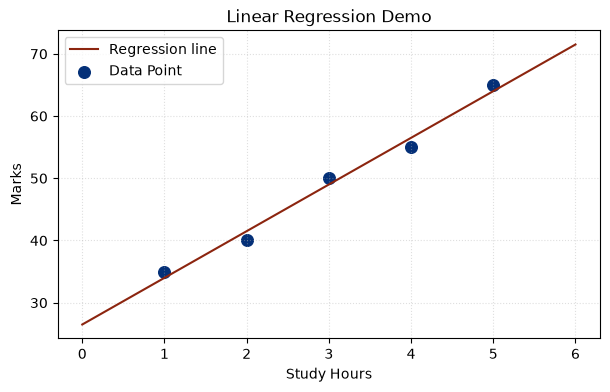

In [33]:
plt.figure(figsize=(7,4))
plt.plot(x, y, color='#8c250f', label = "Regression line", linestyle = '-')
plt.scatter(X, Y, color = '#043078', label = "Data Point", s = 70)
plt.xlabel("Study Hours")
plt.ylabel("Marks")
plt.title("Linear Regression Demo")
plt.grid(True, alpha = 0.4, linestyle = ":") # it helps to know where the point actually lies.
plt.legend(loc = 'best') # it is used to represent symbols and patterns in graph.
plt.show()

In [34]:
# this is made by originally taken X values and their predicted Y values without linspace().
arr_new = []
for i in range(len(X)):
    y = (m * X[i]) + c
    arr_new.append(float(y))

arr_new

[34.0, 41.5, 49.0, 56.5, 64.0]

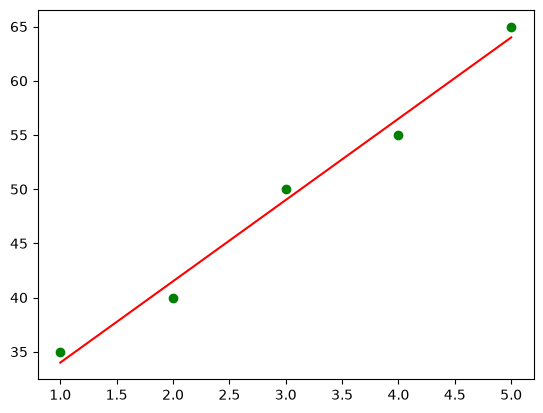

In [35]:
plt.plot(X,arr_new,color = 'r', linestyle = '-' )
plt.scatter(X,Y,color = 'g')
plt.show()

In [36]:
# r2 score
ss_tot = 0
ss_res = 0

for i in range(n):
    y_pred = (m * X[i]) + c
    ss_tot += (Y[i] - mean_y) ** 2
    ss_res += (Y[i] - y_pred) ** 2

r2 = 1 - (ss_res/ss_tot)
print(f"r2 : {r2}")

r2 : 0.9868421052631579


## Verify with Scikit-learn

In [37]:
from sklearn.linear_model import LinearRegression

In [38]:
X = X.reshape(n,1)
X  #2d

array([[1],
       [2],
       [3],
       [4],
       [5]])

In [39]:
lr = LinearRegression()
reg = lr.fit(X,Y)

In [40]:
reg

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[7.5]
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,26.5
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](1,)",[3.16]


In [41]:
R2 = reg.score(X,Y)
print(f'R2 : {R2}')

R2 : 0.9868421052631579
